In [1]:
import sys
import json

from pathlib import Path

import joblib
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import (
    train_test_split,
)

from sklearn.ensemble import (
    RandomForestClassifier,
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    roc_curve,
)



# Project Paths


PROJECT_ROOT = (
    Path.cwd()
    .resolve()
    .parent
)

SRC_DIR = (
    PROJECT_ROOT
    / "src"
)


if str(SRC_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(SRC_DIR),
    )



# Project Modules

# add original folder into PYTHONPATH
project_root = Path().resolve().parent   
sys.path.append(str(project_root))
from ml.churn_model.models.pipeline import (
    build_model_pipeline,
)

from ml.churn_model.models.evaluate import (
    evaluate_classifier,
)

from ml.churn_model.models.predict import (
    ChurnPredictor,
)



# Artifact Paths


RAW_DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)


MODEL_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "models"
)


METRICS_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "metrics"
)


EVALUATION_DIR = (
    PROJECT_ROOT
    / "artifacts"
    / "evaluation"
)


MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

EVALUATION_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


print(
    "Project root:",
    PROJECT_ROOT,
)

print(
    "Raw dataset:",
    RAW_DATA_PATH,
)

print(
    "Model directory:",
    MODEL_DIR,
)

print(
    "Metrics directory:",
    METRICS_DIR,
)

print(
    "Evaluation directory:",
    EVALUATION_DIR,
)



# Load Raw Dataset


df = pd.read_csv(
    RAW_DATA_PATH
)


print(
    "\nDataset shape:",
    df.shape,
)


df.head()

Project root: D:\Research_Project\customer-churn-prediction
Raw dataset: D:\Research_Project\customer-churn-prediction\data\raw\WA_Fn-UseC_-Telco-Customer-Churn.csv
Model directory: D:\Research_Project\customer-churn-prediction\artifacts\models
Metrics directory: D:\Research_Project\customer-churn-prediction\artifacts\metrics
Evaluation directory: D:\Research_Project\customer-churn-prediction\artifacts\evaluation

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# Target Distribution
print(
    "Customer counts:"
)

df["Churn"].value_counts()


print(
    "\nCustomer proportions:"
)


df["Churn"].value_counts(
        normalize=True
    ).round(4)


Customer counts:

Customer proportions:


Churn
No     0.7346
Yes    0.2654
Name: proportion, dtype: float64

In [3]:
#Encode target
# Split Features and Target
TARGET_COLUMN = "Churn"


X = df.drop(
    columns=[
        TARGET_COLUMN
    ]
)


y = (
    df[
        TARGET_COLUMN
    ]
    .map(
        {
            "No": 0,
            "Yes": 1,
        }
    )
)


print(
    "X shape:",
    X.shape,
)

print(
    "y shape:",
    y.shape,
)


print(
    "\nTarget counts:"
)

print(
    y.value_counts()
)

X shape: (7043, 20)
y shape: (7043,)

Target counts:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [4]:
#Train/Test split
X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y,
    )
)


print(
    "X_train:",
    X_train.shape,
)

print(
    "X_test:",
    X_test.shape,
)

print(
    "y_train:",
    y_train.shape,
)

print(
    "y_test:",
    y_test.shape,
)

X_train: (5634, 20)
X_test: (1409, 20)
y_train: (5634,)
y_test: (1409,)


In [5]:
#check churn distribution
# Verify Stratified Split
print(
    "Train churn rate:"
)

print(
    y_train.value_counts(
        normalize=True
    ).round(4)
)


print(
    "\nTest churn rate:"
)

print(
    y_test.value_counts(
        normalize=True
    ).round(4)
)

Train churn rate:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64

Test churn rate:
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64


In [6]:

# Load Selected Model Configuration

SELECTED_MODEL_CONFIG_PATH = (
    MODEL_DIR
    / "selected_model_config.json"
)


if not SELECTED_MODEL_CONFIG_PATH.exists():

    raise FileNotFoundError(
        "Selected model configuration "
        "was not found: "
        f"{SELECTED_MODEL_CONFIG_PATH}"
    )


with open(
    SELECTED_MODEL_CONFIG_PATH,
    "r",
    encoding="utf-8",
) as file:

    selected_model_config = (
        json.load(file)
    )


print(
    "Selected model configuration:"
)


print(
    json.dumps(
        selected_model_config,
        indent=4,
    )
)

Selected model configuration:
{
    "model_name": "Random Forest - Tuned",
    "classifier": "RandomForestClassifier",
    "decision_threshold": 0.47999999999999987,
    "model_selection_metric": "ROC-AUC",
    "threshold_selection_metric": "F1",
    "hyperparameters": {
        "n_estimators": 250,
        "max_depth": 8,
        "min_samples_split": 6,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": "balanced",
        "random_state": 42
    },
    "metrics": {
        "accuracy": 0.7551454932576295,
        "precision": 0.5253940455341506,
        "recall": 0.8021390374331551,
        "f1": 0.6349206349206349,
        "roc_auc": 0.8419230669870056,
        "pr_auc": 0.6523944849375903
    }
}


In [7]:
#Build Tuned Random Forest + End-to-End Pipeline
#Build Final Tuned Random Forest Classifier
rf_params = (
    selected_model_config[
        "hyperparameters"
    ]
)


classifier = (
    RandomForestClassifier(

        n_estimators=
            rf_params[
                "n_estimators"
            ],

        max_depth=
            rf_params[
                "max_depth"
            ],

        min_samples_split=
            rf_params[
                "min_samples_split"
            ],

        min_samples_leaf=
            rf_params[
                "min_samples_leaf"
            ],

        max_features=
            rf_params[
                "max_features"
            ],

        class_weight=
            rf_params[
                "class_weight"
            ],

        random_state=
            rf_params[
                "random_state"
            ],

        n_jobs=-1,
    )
)


print(
    "Final classifier:"
)

print(
    classifier
)



# Build Full End-to-End Pipeline

churn_pipeline = (
    build_model_pipeline(
        X_train=X_train,
        classifier=classifier,
    )
)


print(
    "\nPipeline:"
)

print(
    churn_pipeline
)

Final classifier:
RandomForestClassifier(class_weight='balanced', max_depth=8, min_samples_leaf=2,
                       min_samples_split=6, n_estimators=250, n_jobs=-1,
                       random_state=42)

Pipeline:
Pipeline(steps=[('cleaning',
                 FunctionTransformer(func=<function clean_model_input at 0x000002533FC322A0>)),
                ('feature_engineering',
                 FunctionTransformer(func=<function engineer_features at 0x000002533FC80670>)),
                ('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())...
                                                   'MultipleLines',
       

In [8]:

# Train End-to-End Pipeline

churn_pipeline.fit(
    X_train,
    y_train,
)



# Predict Churn Probabilities


y_probability = (
    churn_pipeline
    .predict_proba(
        X_test
    )[:, 1]
)



# Load Optimized Decision Threshold


if (
    "decision_threshold"
    in selected_model_config
):

    decision_threshold = float(
        selected_model_config[
            "decision_threshold"
        ]
    )

elif (
    "threshold"
    in selected_model_config
):

    # Backward compatibility
    decision_threshold = float(
        selected_model_config[
            "threshold"
        ]
    )

else:

    raise KeyError(
        "selected_model_config.json "
        "does not contain "
        "'decision_threshold' "
        "or 'threshold'."
    )


# Apply Optimized Threshold


y_pred = (
    y_probability
    >= decision_threshold
).astype(int)


print(
    "Decision threshold:",
    round(
        decision_threshold,
        4,
    )
)


print(
    "\nFirst predictions:"
)

print(
    y_pred[:10]
)


print(
    "\nFirst probabilities:"
)

print(
    y_probability[:10]
)

Decision threshold: 0.48

First predictions:
[0 1 0 1 0 1 1 0 0 1]

First probabilities:
[0.04501091 0.87168202 0.15760917 0.61957656 0.05796483 0.7278096
 0.62366856 0.25536175 0.02018018 0.56562141]


In [9]:
# Evaluate Production Pipeline
pipeline_metrics = (
    evaluate_classifier(
        "End-to-End Tuned Random Forest",
        y_test,
        y_pred,
        y_probability,
    )
)


pipeline_metrics_df = (
    pd.DataFrame(
        [
            pipeline_metrics
        ]
    ).round(4)
)
pipeline_metrics_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,End-to-End Tuned Random Forest,0.7566,0.527,0.8102,0.6386,0.842,0.652


In [10]:
#Classification Report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Churn",
            "Churn",
        ],
        zero_division=0,
    )
)

              precision    recall  f1-score   support

    No Churn       0.91      0.74      0.82      1035
       Churn       0.53      0.81      0.64       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



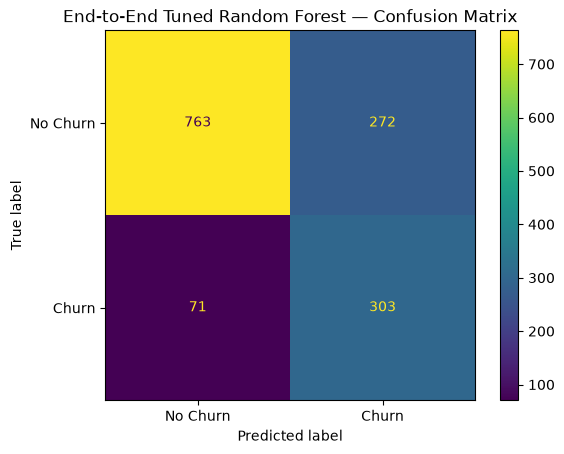

In [11]:
# Confusion Matrix Visualization
cm = confusion_matrix(
    y_test,
    y_pred,
)


cm_display = (
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "No Churn",
            "Churn",
        ],
    )
)


cm_display.plot()


plt.title(
    "End-to-End Tuned Random Forest — Confusion Matrix"
)


plt.show()

In [12]:
#Export Confusion Matrix Artifact
cm = confusion_matrix(
    y_test,
    y_pred,
)


tn, fp, fn, tp = (
    cm.ravel()
)


confusion_matrix_artifact = {

    "true_negative":
        int(tn),

    "false_positive":
        int(fp),

    "false_negative":
        int(fn),

    "true_positive":
        int(tp),

    "matrix": [
        [
            int(tn),
            int(fp),
        ],
        [
            int(fn),
            int(tp),
        ],
    ],

    "labels": [
        "No Churn",
        "Churn",
    ],
}


CONFUSION_MATRIX_PATH = (
    EVALUATION_DIR
    / "confusion_matrix.json"
)


with open(
    CONFUSION_MATRIX_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        confusion_matrix_artifact,
        file,
        indent=4,
    )


print(
    "Confusion matrix artifact saved:"
)

print(
    CONFUSION_MATRIX_PATH
)

Confusion matrix artifact saved:
D:\Research_Project\customer-churn-prediction\artifacts\evaluation\confusion_matrix.json


In [13]:
# ROC-AUC
roc_auc = roc_auc_score(
    y_test,
    y_probability,
)


print(
    f"ROC-AUC: "
    f"{roc_auc:.4f}"
)

ROC-AUC: 0.8420


In [14]:
# Export ROC Curve Artifact
fpr, tpr, roc_thresholds = (
    roc_curve(
        y_test,
        y_probability,
    )
)


roc_points = [

    {
        "fpr":
            round(
                float(
                    fpr_value
                ),
                6,
            ),

        "tpr":
            round(
                float(
                    tpr_value
                ),
                6,
            ),
    }

    for (
        fpr_value,
        tpr_value,
    )

    in zip(
        fpr,
        tpr,
    )
]


roc_curve_artifact = {

    "auc":
        float(
            roc_auc
        ),

    "points":
        roc_points,
}


ROC_CURVE_PATH = (
    EVALUATION_DIR
    / "roc_curve.json"
)


with open(
    ROC_CURVE_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        roc_curve_artifact,
        file,
        indent=4,
    )


print(
    "ROC curve artifact saved:"
)

print(
    ROC_CURVE_PATH
)


print(
    "\nNumber of ROC points:",
    len(
        roc_points
    )
)

ROC curve artifact saved:
D:\Research_Project\customer-churn-prediction\artifacts\evaluation\roc_curve.json

Number of ROC points: 382


In [15]:
#PR-AUC
pr_auc = (
    average_precision_score(
        y_test,
        y_probability,
    )
)


print(
    f"PR-AUC: "
    f"{pr_auc:.4f}"
)

PR-AUC: 0.6520


In [16]:
# Save Production Pipeline Metrics
metrics_df = pd.DataFrame([
    pipeline_metrics
])

METRICS_PATH = (
    METRICS_DIR
    / "end_to_end_pipeline_metrics.csv"
)


pipeline_metrics_df.to_csv(
    METRICS_PATH,
    index=False,
)


print(
    "Production pipeline metrics saved:"
)

print(
    METRICS_PATH
)



pipeline_metrics_df.round(4)



Production pipeline metrics saved:
D:\Research_Project\customer-churn-prediction\artifacts\metrics\end_to_end_pipeline_metrics.csv


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,End-to-End Tuned Random Forest,0.7566,0.527,0.8102,0.6386,0.842,0.652


In [17]:
# Save Full Production Pipeline
MODEL_PATH = (
    MODEL_DIR
    / "churn_pipeline.joblib"
)


joblib.dump(
    churn_pipeline,
    MODEL_PATH,
)


print(
    "Production pipeline saved:"
)

print(
    MODEL_PATH
)


print(
    "\nExists:",
    MODEL_PATH.exists()
)

Production pipeline saved:
D:\Research_Project\customer-churn-prediction\artifacts\models\churn_pipeline.joblib

Exists: True


In [18]:
#Test saved pipeline
# Reload and Verify Saved Pipeline
loaded_pipeline = joblib.load(
    MODEL_PATH
)


loaded_probabilities = (
    loaded_pipeline
    .predict_proba(
        X_test
    )[:, 1]
)


loaded_predictions = (
    loaded_probabilities
    >= decision_threshold
).astype(int)


print(
    "First predictions:"
)

print(
    loaded_predictions[:5]
)


print(
    "\nFirst probabilities:"
)

print(
    loaded_probabilities[:5]
)


print(
    "\nPredictions match:",
    (
        loaded_predictions
        == y_pred
    ).all()
)

First predictions:
[0 1 0 1 0]

First probabilities:
[0.04501091 0.87168202 0.15760917 0.61957656 0.05796483]

Predictions match: True


In [19]:
# Test One Raw Customer
sample_customer = (
    X_test
    .iloc[
        [0]
    ]
    .copy()
)
sample_customer


probability = (
    loaded_pipeline
    .predict_proba(
        sample_customer
    )[0, 1]
)


prediction = int(
    probability
    >= decision_threshold
)


print(
    "Prediction:",
    prediction
)


print(
    f"Churn probability: "
    f"{probability:.2%}"
)


print(
    f"Decision threshold: "
    f"{decision_threshold:.2%}"
)

Prediction: 0
Churn probability: 4.50%
Decision threshold: 48.00%


In [20]:
# Convert Prediction into Business Output
prediction_label = (
    "Churn"
    if prediction == 1
    else "No Churn"
)


print(
    "Prediction:",
    prediction_label
)


print(
    f"Churn probability: "
    f"{probability:.2%}"
)


print(
    f"Decision threshold: "
    f"{decision_threshold:.2%}"
)

Prediction: No Churn
Churn probability: 4.50%
Decision threshold: 48.00%


In [21]:
# Test New Raw Customer
new_customer = pd.DataFrame(
    [
        {
            "gender":
                "Female",

            "SeniorCitizen":
                0,

            "Partner":
                "No",

            "Dependents":
                "No",

            "tenure":
                5,

            "PhoneService":
                "Yes",

            "MultipleLines":
                "No",

            "InternetService":
                "Fiber optic",

            "OnlineSecurity":
                "No",

            "OnlineBackup":
                "No",

            "DeviceProtection":
                "No",

            "TechSupport":
                "No",

            "StreamingTV":
                "Yes",

            "StreamingMovies":
                "Yes",

            "Contract":
                "Month-to-month",

            "PaperlessBilling":
                "Yes",

            "PaymentMethod":
                "Electronic check",

            "MonthlyCharges":
                95.50,

            "TotalCharges":
                477.50,
        }
    ]
)


new_customer_probability = (
    loaded_pipeline
    .predict_proba(
        new_customer
    )[0, 1]
)


new_customer_prediction = int(
    new_customer_probability
    >= decision_threshold
)


print(
    "Prediction:",
    (
        "Churn"
        if new_customer_prediction == 1
        else "No Churn"
    ),
)


print(
    f"Probability: "
    f"{new_customer_probability:.2%}"
)


print(
    f"Threshold: "
    f"{decision_threshold:.2%}"
)

Prediction: Churn
Probability: 89.23%
Threshold: 48.00%


In [22]:
#Test Using predictor
predictor = ChurnPredictor(
    MODEL_PATH
)
customer = {
    "gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "tenure": 5,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.50,
    "TotalCharges": 477.50,
}
churn_probability = (
    predictor.predict_probability(
        customer
    )
)

print(
    f"Churn probability: "
    f"{churn_probability:.2%}"
)

Churn probability: 89.23%


In [23]:
#Test custom threshold
#threshold=0.38 from optimization
threshold = 0.5

churn_probability = (
    predictor.predict_probability(
        customer
    )
)

prediction = int(
    churn_probability
    >= threshold
)

prediction_label = (
    "Churn"
    if prediction == 1
    else "No Churn"
)

print(
    "Prediction:",
    prediction_label
)

print(
    f"Churn probability: "
    f"{churn_probability:.2%}"
)

Prediction: Churn
Churn probability: 89.23%


In [24]:
# Test ChurnPredictor
predictor = ChurnPredictor(
    MODEL_PATH
)


customer = {

    "gender": "Female",

    "SeniorCitizen": 0,

    "Partner": "No",

    "Dependents": "No",

    "tenure": 5,

    "PhoneService": "Yes",

    "MultipleLines": "No",

    "InternetService":
        "Fiber optic",

    "OnlineSecurity": "No",

    "OnlineBackup": "No",

    "DeviceProtection": "No",

    "TechSupport": "No",

    "StreamingTV": "Yes",

    "StreamingMovies": "Yes",

    "Contract":
        "Month-to-month",

    "PaperlessBilling": "Yes",

    "PaymentMethod":
        "Electronic check",

    "MonthlyCharges": 95.50,

    "TotalCharges": 477.50,
}


churn_probability = (
    predictor
    .predict_probability(
        customer
    )
)


print(
    f"Churn probability: "
    f"{churn_probability:.2%}"
)

Churn probability: 89.23%


In [25]:
# Test ChurnPredictor with Optimized Threshold
churn_probability = (
    predictor
    .predict_probability(
        customer
    )
)


prediction = int(
    churn_probability
    >= decision_threshold
)


prediction_label = (
    "Churn"
    if prediction == 1
    else "No Churn"
)


print(
    "Prediction:",
    prediction_label
)


print(
    f"Churn probability: "
    f"{churn_probability:.2%}"
)


print(
    f"Optimized threshold: "
    f"{decision_threshold:.2%}"
)

Prediction: Churn
Churn probability: 89.23%
Optimized threshold: 48.00%


In [26]:
import json
# Save Production Pipeline Metadata
classifier_step = (
    churn_pipeline
    .named_steps[
        "classifier"
    ]
)


metadata = {

    "model_name":
        "End-to-End Tuned Random Forest",

    "model_version":
        "1.0.0",

    "algorithm":
        type(
            classifier_step
        ).__name__,

    "task":
        "Binary Classification",

    "target":
        "Churn",

    "positive_class":
        "Churn",

    "negative_class":
        "No Churn",

    "decision_threshold":
        float(
            decision_threshold
        ),

    "model_selection_metric":
        selected_model_config.get(
            "model_selection_metric",
            "ROC-AUC",
        ),

    "threshold_selection_metric":
        selected_model_config.get(
            "threshold_selection_metric",
            "F1",
        ),

    "test_size":
        0.20,

    "random_state":
        42,

    "features_source":
        "IBM Telco Customer Churn",

    "status":
        "Production",

    "artifacts": {

        "pipeline":
            "churn_pipeline.joblib",

        "metrics":
            "end_to_end_pipeline_metrics.csv",

        "confusion_matrix":
            "confusion_matrix.json",

        "roc_curve":
            "roc_curve.json",
    },

    "metrics": {

        "accuracy":
            float(
                pipeline_metrics[
                    "Accuracy"
                ]
            ),

        "precision":
            float(
                pipeline_metrics[
                    "Precision"
                ]
            ),

        "recall":
            float(
                pipeline_metrics[
                    "Recall"
                ]
            ),

        "f1":
            float(
                pipeline_metrics[
                    "F1"
                ]
            ),

        "roc_auc":
            float(
                pipeline_metrics[
                    "ROC-AUC"
                ]
            ),

        "pr_auc":
            float(
                pipeline_metrics[
                    "PR-AUC"
                ]
            ),
    },
}


METADATA_PATH = (
    MODEL_DIR
    / "churn_pipeline_metadata.json"
)


with open(
    METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        metadata,
        file,
        indent=4,
    )


print(
    "Pipeline metadata saved:"
)

print(
    METADATA_PATH
)


print(
    "\nMetadata:"
)


print(
    json.dumps(
        metadata,
        indent=4,
    )
)

Pipeline metadata saved:
D:\Research_Project\customer-churn-prediction\artifacts\models\churn_pipeline_metadata.json

Metadata:
{
    "model_name": "End-to-End Tuned Random Forest",
    "model_version": "1.0.0",
    "algorithm": "RandomForestClassifier",
    "task": "Binary Classification",
    "target": "Churn",
    "positive_class": "Churn",
    "negative_class": "No Churn",
    "decision_threshold": 0.47999999999999987,
    "model_selection_metric": "ROC-AUC",
    "threshold_selection_metric": "F1",
    "test_size": 0.2,
    "random_state": 42,
    "features_source": "IBM Telco Customer Churn",
    "status": "Production",
    "artifacts": {
        "pipeline": "churn_pipeline.joblib",
        "metrics": "end_to_end_pipeline_metrics.csv",
        "confusion_matrix": "confusion_matrix.json",
        "roc_curve": "roc_curve.json"
    },
    "metrics": {
        "accuracy": 0.7565649396735273,
        "precision": 0.5269565217391304,
        "recall": 0.8101604278074866,
        "f1": 0

In [27]:
# Test Missing Value Handling
missing_customer = (
    new_customer.copy()
)


missing_customer[
    "TotalCharges"
] = None


missing_probability = (
    loaded_pipeline
    .predict_proba(
        missing_customer
    )[0, 1]
)


missing_prediction = int(
    missing_probability
    >= decision_threshold
)


print(
    "Prediction:",
    (
        "Churn"
        if missing_prediction == 1
        else "No Churn"
    )
)


print(
    f"Probability: "
    f"{missing_probability:.2%}"
)


Prediction: Churn
Probability: 82.79%


In [ ]:
#Final Artifact Verification
artifacts_to_check = {

    "Production pipeline":
        MODEL_PATH,

    "Pipeline metadata":
        METADATA_PATH,

    "Pipeline metrics":
        METRICS_PATH,

    "Confusion matrix":
        CONFUSION_MATRIX_PATH,

    "ROC curve":
        ROC_CURVE_PATH,

    "Selected model config":
        SELECTED_MODEL_CONFIG_PATH,

   
}


for name, path in artifacts_to_check.items():

    status = (
        "OK"
        if path.exists()
        else "MISSING"
    )

    print(
        f"{status:8} | "
        f"{name:24} | "
        f"{path}"
    )


print(
    "\nLoaded model type:"
)


verified_model = joblib.load(
    MODEL_PATH
)


print(
    type(
        verified_model
    )
)


print(
    "\nPipeline steps:"
)


print(
    verified_model
    .named_steps
    .keys()
)


print(
    "\nClassifier:"
)


print(
    type(
        verified_model
        .named_steps[
            "classifier"
        ]
    ).__name__
)


print(
    "\nDecision threshold:"
)


print(
    decision_threshold
)

OK       | Production pipeline      | D:\Research_Project\customer-churn-prediction\artifacts\models\churn_pipeline.joblib
OK       | Pipeline metadata        | D:\Research_Project\customer-churn-prediction\artifacts\models\churn_pipeline_metadata.json
OK       | Pipeline metrics         | D:\Research_Project\customer-churn-prediction\artifacts\metrics\end_to_end_pipeline_metrics.csv
OK       | Confusion matrix         | D:\Research_Project\customer-churn-prediction\artifacts\evaluation\confusion_matrix.json
OK       | ROC curve                | D:\Research_Project\customer-churn-prediction\artifacts\evaluation\roc_curve.json
OK       | Selected model config    | D:\Research_Project\customer-churn-prediction\artifacts\models\selected_model_config.json

Loaded model type:
<class 'sklearn.pipeline.Pipeline'>

Pipeline steps:
dict_keys(['cleaning', 'feature_engineering', 'preprocessor', 'classifier'])

Classifier:
RandomForestClassifier

Decision threshold:
0.47999999999999987


In [29]:
# Extract Random Forest Feature Importance
classifier_step = (
    churn_pipeline
    .named_steps[
        "classifier"
    ]
)


preprocessor_step = (
    churn_pipeline
    .named_steps[
        "preprocessor"
    ]
)


print(
    "Classifier:",
    type(
        classifier_step
    ).__name__
)


if not hasattr(
    classifier_step,
    "feature_importances_",
):

    raise ValueError(
        "The production classifier does not "
        "support feature_importances_."
    )


feature_importances = (
    classifier_step
    .feature_importances_
)


print(
    "Number of importance values:",
    len(
        feature_importances
    )
)

Classifier: RandomForestClassifier
Number of importance values: 64


In [30]:
# Get Transformed Feature Names
feature_names = (
    preprocessor_step
    .get_feature_names_out()
)


print(
    "Number of transformed features:",
    len(
        feature_names
    )
)


print(
    "\nFirst transformed features:"
)


for feature_name in feature_names[:20]:

    print(
        feature_name
    )

Number of transformed features: 64

First transformed features:
numerical__SeniorCitizen
numerical__tenure
numerical__MonthlyCharges
numerical__TotalCharges
numerical__is_new_customer
numerical__is_loyal_customer
numerical__avg_monthly_spend
numerical__customer_value
numerical__is_long_term_contract
numerical__automatic_payment
numerical__is_electronic_check
numerical__has_tech_support
numerical__has_online_security
numerical__num_support_services
numerical__has_support_service
numerical__num_services
numerical__uses_streaming
numerical__charges_per_service
numerical__has_family
categorical__gender_Female


In [ ]:
#checking match
assert (
    len(feature_names)
    ==
    len(feature_importances)
)
print(
    "Feature names and importances match."
)

Feature names and importances match.


In [32]:
# Build Raw Feature Importance DataFrame
raw_feature_importance_df = (
    pd.DataFrame(
        {
            "transformed_feature":
                feature_names,

            "importance":
                feature_importances,
        }
    )
)


raw_feature_importance_df = (
    raw_feature_importance_df
    .sort_values(
        by="importance",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


display(
    raw_feature_importance_df
    .head(20)
)

,transformed_feature,importance
0,categorical__Contract_Month-to-month,0.110164
1,numerical__is_long_term_contract,0.105821
2,numerical__charges_per_service,0.060740
3,numerical__tenure,0.058937
4,categorical__OnlineSecurity_No,0.046948
5,categorical__Contract_Two year,0.045927
6,numerical__customer_value,0.044224
7,categorical__TechSupport_No,0.042948
8,numerical__MonthlyCharges,0.042692
9,numerical__TotalCharges,0.042565


In [33]:
# Aggregate One-Hot Features
# back to Original Business Features
input_features = list(
    preprocessor_step
    .feature_names_in_
)


print(
    "Features entering preprocessor:"
)


print(
    input_features
)

Features entering preprocessor:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'tenure_group', 'is_new_customer', 'is_loyal_customer', 'avg_monthly_spend', 'customer_value', 'is_long_term_contract', 'automatic_payment', 'is_electronic_check', 'has_tech_support', 'has_online_security', 'num_support_services', 'has_support_service', 'num_services', 'uses_streaming', 'charges_per_service', 'has_family']


In [35]:
def resolve_original_feature(
    transformed_feature: str,
    candidate_features: list[str],
) -> str:

    # Remove ColumnTransformer prefix
    #
    # Examples:
    # num__tenure
    # cat__Contract_Month-to-month

    clean_name = (
        transformed_feature
        .split(
            "__",
            1,
        )[-1]
    )


    # Longer names first prevents
    # partial-name collisions
    candidates = sorted(
        candidate_features,
        key=len,
        reverse=True,
    )


    for feature in candidates:

        # Numerical feature
        if clean_name == feature:

            return feature


        # One-hot encoded categorical feature
        if clean_name.startswith(
            f"{feature}_"
        ):

            return feature


    # Fallback
    return clean_name

raw_feature_importance_df[
    "feature"
] = (

    raw_feature_importance_df[
        "transformed_feature"
    ]

    .apply(
        lambda name:
            resolve_original_feature(
                name,
                input_features,
            )
    )
)

In [37]:
# Aggregate Feature Importances
feature_importance_df = (

    raw_feature_importance_df

    .groupby(
        "feature",
        as_index=False,
    )[
        "importance"
    ]

    .sum()

    .sort_values(
        by="importance",
        ascending=False,
    )

    .reset_index(
        drop=True
    )
)
#create percentage
total_importance = (
    feature_importance_df[
        "importance"
    ]
    .sum()
)


feature_importance_df[
    "percentage"
] = (

    feature_importance_df[
        "importance"
    ]

    / total_importance

    * 100
)

#rank
feature_importance_df[
    "rank"
] = (
    range(
        1,
        len(
            feature_importance_df
        ) + 1,
    )
)

display(
    feature_importance_df
    .head(15)
    .round(4)
)

,feature,importance,percentage,rank
0,Contract,0.1660,16.5960,1
1,is_long_term_contract,0.1058,10.5821,2
2,charges_per_service,0.0607,6.0740,3
3,tenure,0.0589,5.8937,4
4,OnlineSecurity,0.0582,5.8169,5
5,InternetService,0.0558,5.5837,6
6,TechSupport,0.0499,4.9881,7
7,customer_value,0.0442,4.4224,8
8,MonthlyCharges,0.0427,4.2692,9
9,TotalCharges,0.0426,4.2565,10


In [38]:
#check total importance
print(
    "Raw importance total:",
    raw_feature_importance_df[
        "importance"
    ].sum()
)


print(
    "Aggregated importance total:",
    feature_importance_df[
        "importance"
    ].sum()
)


print(
    "Percentage total:",
    feature_importance_df[
        "percentage"
    ].sum()
)

Raw importance total: 1.0
Aggregated importance total: 0.9999999999999998
Percentage total: 100.00000000000003


In [40]:
# Export Feature Importance Artifact
TOP_N_FEATURES = 15


top_features = (
    feature_importance_df
    .head(
        TOP_N_FEATURES
    )
)


feature_importance_artifact = {

    "model_name":
        metadata.get(
            "model_name",
            "End-to-End Tuned Random Forest",
        ),

    "algorithm":
        type(
            classifier_step
        ).__name__,

    "method":
        "Random Forest impurity-based feature importance",

    "total_transformed_features":
        int(
            len(
                raw_feature_importance_df
            )
        ),

    "total_business_features":
        int(
            len(
                feature_importance_df
            )
        ),

    "top_n":
        int(
            TOP_N_FEATURES
        ),

    "features": [

        {
            "rank":
                int(
                    row["rank"]
                ),

            "feature":
                str(
                    row["feature"]
                ),

            "importance":
                float(
                    row["importance"]
                ),

            "percentage":
                float(
                    row["percentage"]
                ),
        }

        for _, row
        in top_features.iterrows()
    ],
}

FEATURE_IMPORTANCE_PATH = (
    EVALUATION_DIR
    / "feature_importance.json"
)


with open(
    FEATURE_IMPORTANCE_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        feature_importance_artifact,
        file,
        indent=4,
    )


print(
    "Feature importance saved:"
)


print(
    FEATURE_IMPORTANCE_PATH
)

Feature importance saved:
D:\Research_Project\customer-churn-prediction\artifacts\evaluation\feature_importance.json


In [41]:
#checking
print(
    json.dumps(
        feature_importance_artifact,
        indent=4,
    )
)

{
    "model_name": "End-to-End Tuned Random Forest",
    "algorithm": "RandomForestClassifier",
    "method": "Random Forest impurity-based feature importance",
    "total_transformed_features": 64,
    "total_business_features": 35,
    "top_n": 15,
    "features": [
        {
            "rank": 1,
            "feature": "Contract",
            "importance": 0.16596019699194847,
            "percentage": 16.59601969919485
        },
        {
            "rank": 2,
            "feature": "is_long_term_contract",
            "importance": 0.10582124133045875,
            "percentage": 10.582124133045879
        },
        {
            "rank": 3,
            "feature": "charges_per_service",
            "importance": 0.06073967191924824,
            "percentage": 6.073967191924826
        },
        {
            "rank": 4,
            "feature": "tenure",
            "importance": 0.05893671038321282,
            "percentage": 5.893671038321283
        },
        {
            "rank

In [42]:
artifacts_to_check = {

    "Production pipeline":
        MODEL_PATH,

    "Pipeline metadata":
        METADATA_PATH,

    "Pipeline metrics":
        METRICS_PATH,

    "Confusion matrix":
        CONFUSION_MATRIX_PATH,

    "ROC curve":
        ROC_CURVE_PATH,

    "Feature importance":
        FEATURE_IMPORTANCE_PATH,

    "Selected model config":
        SELECTED_MODEL_CONFIG_PATH,
}

artifacts_to_check

{'Production pipeline': WindowsPath('D:/Research_Project/customer-churn-prediction/artifacts/models/churn_pipeline.joblib'),
 'Pipeline metadata': WindowsPath('D:/Research_Project/customer-churn-prediction/artifacts/models/churn_pipeline_metadata.json'),
 'Pipeline metrics': WindowsPath('D:/Research_Project/customer-churn-prediction/artifacts/metrics/end_to_end_pipeline_metrics.csv'),
 'Confusion matrix': WindowsPath('D:/Research_Project/customer-churn-prediction/artifacts/evaluation/confusion_matrix.json'),
 'ROC curve': WindowsPath('D:/Research_Project/customer-churn-prediction/artifacts/evaluation/roc_curve.json'),
 'Feature importance': WindowsPath('D:/Research_Project/customer-churn-prediction/artifacts/evaluation/feature_importance.json'),
 'Selected model config': WindowsPath('D:/Research_Project/customer-churn-prediction/artifacts/models/selected_model_config.json')}